# ✨ Spatial Filtering — edges, sharpening & high-boost

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/negarsh76/Digital-Image-Processing/blob/main/notebooks/03_spatial_filtering.ipynb)

A hand-written 2-D convolution is used to apply classic masks: **Laplacian** (4- and 8-neighbour), **Sobel**, **Roberts** and **Prewitt** edge detectors, then **unsharp masking** and **high-boost filtering** for sharpening.

In [1]:
# On Colab, uncomment:
# !pip -q install scikit-image opencv-python-headless

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import data, img_as_float
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "image.cmap": "gray"})
ASSETS = Path("../assets"); ASSETS.mkdir(exist_ok=True)

def show(images, titles, ncols=None, figsize=None, save=None, cmap="gray"):
    """Plot a row/grid of images with titles; optionally save to assets/."""
    n = len(images); ncols = ncols or n; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize or (3.2 * ncols, 3.2 * nrows))
    for ax, im, t in zip(np.ravel(axes), images, titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else cmap); ax.set_title(t); ax.axis("off")
    for ax in np.ravel(axes)[n:]: ax.axis("off")
    fig.tight_layout()
    if save: fig.savefig(ASSETS / save, bbox_inches="tight", dpi=120)
    plt.show()

def psnr(ref, img):
    mse = np.mean((np.asarray(ref, float) - np.asarray(img, float)) ** 2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


In [3]:
def conv2d(im, k):
    """2-D convolution with symmetric padding, written with NumPy stride tricks."""
    k = np.flipud(np.fliplr(np.asarray(k, float)))
    ph, pw = k.shape[0] // 2, k.shape[1] // 2
    pad = np.pad(im, ((ph, k.shape[0] - 1 - ph), (pw, k.shape[1] - 1 - pw)), mode="symmetric")
    win = np.lib.stride_tricks.sliding_window_view(pad, k.shape)
    return np.einsum("ijkl,kl->ij", win, k)

img = img_as_float(data.chelsea()[..., 0])

# verify against SciPy
from scipy.ndimage import convolve
k = np.random.rand(5, 5)
print("max |ours - scipy| =", np.abs(conv2d(img, k) - convolve(img, k, mode="reflect")).max())

max |ours - scipy| = 5.329070518200751e-15


## Edge-detection masks

| Mask | Kernel | Responds to |
|---|---|---|
| Laplacian-4 | `[[0,1,0],[1,-4,1],[0,1,0]]` | 2nd derivative, isotropic for 90° |
| Laplacian-8 | `[[1,1,1],[1,-8,1],[1,1,1]]` | 2nd derivative incl. diagonals |
| Sobel | `[[-1,-2,-1],[0,0,0],[1,2,1]]` | 1st derivative, smoothed |
| Roberts | `[[-1,0],[0,1]]` | diagonal 1st derivative |

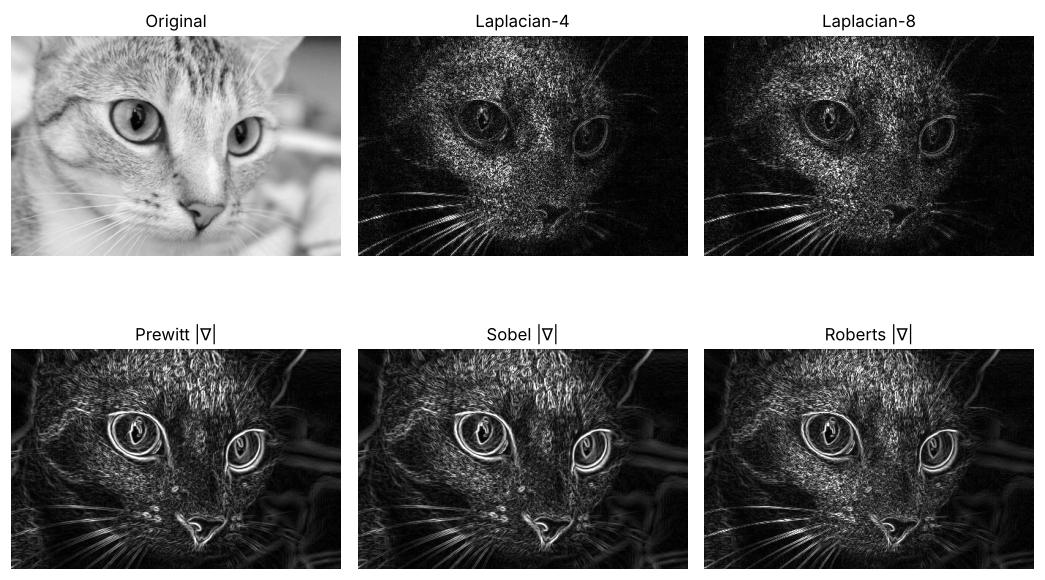

In [4]:
masks = {
    "Laplacian-4": [[0, 1, 0], [1, -4, 1], [0, 1, 0]],
    "Laplacian-8": [[1, 1, 1], [1, -8, 1], [1, 1, 1]],
}
def grad_mag(kx):
    kx = np.asarray(kx, float)
    ky = kx.T if kx.shape[0] == kx.shape[1] and kx.shape[0] > 2 else np.fliplr(kx)
    return np.hypot(conv2d(img, kx), conv2d(img, ky))

out = {
    "Laplacian-4": np.abs(conv2d(img, masks["Laplacian-4"])),
    "Laplacian-8": np.abs(conv2d(img, masks["Laplacian-8"])),
    "Prewitt |∇|": grad_mag([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]),
    "Sobel |∇|":   grad_mag([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Roberts |∇|": grad_mag([[-1, 0], [0, 1]]),
}
norm = lambda x: np.clip(x / np.percentile(x, 99.5), 0, 1)
show([img] + [norm(v) for v in out.values()], ["Original"] + list(out), ncols=3, save="edges.png")

## Laplacian sharpening
$g = f - c\,\nabla^2 f$ (the sign is negative because the Laplacian kernels above have a negative centre).

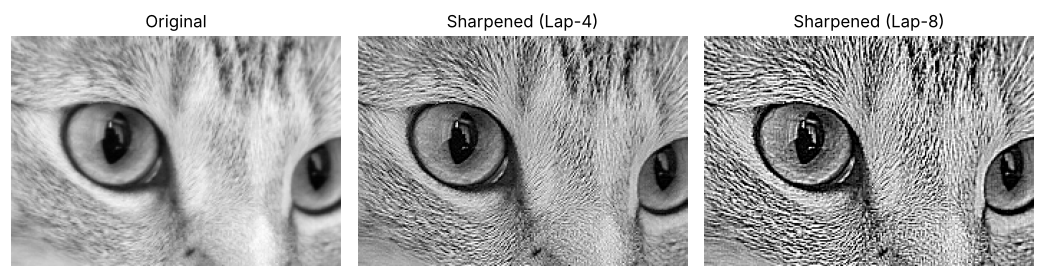

In [5]:
sharp4 = np.clip(img - conv2d(img, masks["Laplacian-4"]), 0, 1)
sharp8 = np.clip(img - conv2d(img, masks["Laplacian-8"]), 0, 1)
crop = np.s_[40:200, 100:330]
show([img[crop], sharp4[crop], sharp8[crop]], ["Original", "Sharpened (Lap-4)", "Sharpened (Lap-8)"], save="laplacian_sharpen.png")

## Unsharp masking & high-boost filtering
1. Blur: $\bar f = f * G_\sigma$
2. Mask: $g_{mask} = f - \bar f$
3. Add back: $g = f + k\, g_{mask}$

$k = 1$ is **unsharp masking**, $k > 1$ is **high-boost**.

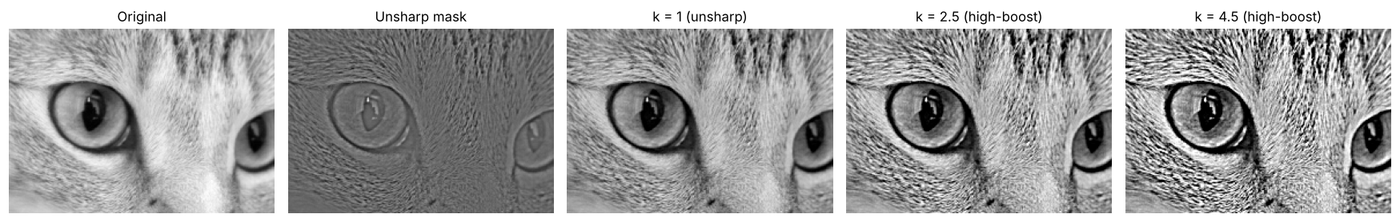

In [6]:
def gaussian_kernel(size=9, sigma=2.0):
    ax = np.arange(size) - size // 2
    g = np.exp(-(ax[:, None]**2 + ax[None, :]**2) / (2 * sigma**2))
    return g / g.sum()

blur = conv2d(img, gaussian_kernel())
mask = img - blur
results = [np.clip(img + k * mask, 0, 1) for k in (1, 2.5, 4.5)]
show([img[crop], (mask[crop] - mask.min()) / np.ptp(mask)] + [r[crop] for r in results],
     ["Original", "Unsharp mask", "k = 1 (unsharp)", "k = 2.5 (high-boost)", "k = 4.5 (high-boost)"],
     ncols=5, save="highboost.png")

### How much sharper? Mean gradient magnitude (a simple sharpness score)

In [7]:
SOBEL = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
score = lambda x: np.hypot(conv2d(x, SOBEL), conv2d(x, SOBEL.T)).mean()
for name, x in [("original", img), ("Laplacian-8", sharp8), ("k=1", results[0]), ("k=2.5", results[1]), ("k=4.5", results[2])]:
    print(f"{name:12s} {score(x):.4f}")

original     0.1905
Laplacian-8  0.7533
k=1          0.3088
k=2.5        0.4868
k=4.5        0.6959
